In [49]:
from math import sqrt
import matplotlib.pyplot as plt
import torch
from torchfem import Truss
from mpl_toolkits.mplot3d import Axes3D

# Dimensions
A = 10  # X axis (length of the bridge)
B = 2   # Y axis (width of the bridge)
C = 2   # Z axis (height of the bridge)

# Nodes
n1 = torch.linspace(0.0, 5.0, A)
n2 = torch.linspace(0.0, 0.5, B)
n3 = torch.linspace(0.0, 0.5, C)
n1, n2, n3 = torch.meshgrid(n1, n2, n3, indexing="xy")
nodes = torch.stack([n1.ravel(), n2.ravel(), n3.ravel()], dim=1)

# Elements
connections = []
# X-axis connections (lengthwise)
for k in range(C):
    for j in range(B):
        for i in range(A - 1):
            connections.append([i + j * A + k * A * B, i + 1 + j * A + k * A * B])
'''
# Y-axis connections (widthwise) - Revised to ensure closest connection
for k in range(C):
    for i in range(A):
        for j in range(B - 1):
            node_a = i + j * A + k * A * B
            node_b =  (i + (j + 1) * A + k * A * B)
            connections.append([node_a, node_b])
'''
# Z-axis connections (heightwise) - Keeping this as it seems fine
for j in range(B):
    for i in range(A):
        for k in range(C-1):
            connections.append([i + j * A + k * A * B, i + j * A + (k + 1) * A * B])



connections.append([1,3])
connections.append([3,5])
connections.append([5,7])
connections.append([7,9])
connections.append([9,11])
connections.append([11,13])
connections.append([13,15])
connections.append([15,17])
connections.append([17,19])
connections.append([21,23])
connections.append([23,25])
connections.append([25,27])
connections.append([27,29])
connections.append([29,31])
connections.append([31,33])
connections.append([33,35])
connections.append([35,37])
connections.append([37,39])
connections.append([36,38])
connections.append([34,36])
connections.append([32,34])
connections.append([30,32])
connections.append([28,30])
connections.append([26,28])
connections.append([24,26])
connections.append([22,24])
connections.append([20,22])
connections.append([2,4])
connections.append([0,2])
connections.append([4,6])
connections.append([6,8])
connections.append([8,10])
connections.append([10,12])
connections.append([12,14])
connections.append([14,16])
connections.append([16,18])
connections.append([10,9])
connections.append([30,29])
connections.append([31,28])
connections.append([3,0])
connections.append([5,2])
connections.append([7,4])
connections.append([9,6])
connections.append([11,8])
connections.append([13,10])
connections.append([15,12])
connections.append([17,14])
connections.append([19,16])
connections.append([23,20])
connections.append([25,22])
connections.append([27,24])
connections.append([29,26])
connections.append([33,30])
connections.append([35,32])
connections.append([37,34])
connections.append([39,36])
connections.append([1,23])
connections.append([3,25])
connections.append([5,27])
connections.append([7,29])
connections.append([9,31])
connections.append([11,33])
connections.append([13,35])
connections.append([15,37])
connections.append([17,39])
connections.append([3,21])
connections.append([5,23])
connections.append([7,25])
connections.append([9,27])
connections.append([11,29])
connections.append([13,31])
connections.append([15,33])
connections.append([17,35])
connections.append([19,37])
connections.append([0,22])
connections.append([2,24])
connections.append([4,26])
connections.append([6,28])
connections.append([8,30])
connections.append([10,32])
connections.append([12,34])
connections.append([14,36])
connections.append([16,38])
connections.append([2,20])
connections.append([4,22])
connections.append([6,24])
connections.append([8,26])
connections.append([10,28])
connections.append([12,30])
connections.append([14,32])
connections.append([16,34])
connections.append([18,36])

elements = torch.tensor(connections)

# Forces at bottom edge
forces = torch.zeros_like(nodes)
forces[2:len(connections):2, 2] = -0.1  # Apply downward force on middle nodes
forces[38,2] = 0.0 
forces[18,2] = 0.0 
forces[20,2] = 0.0
# Constraints by the supports
displacements = torch.zeros_like(nodes)
constraints = torch.zeros_like(nodes, dtype=bool)
#constraints = torch.zeros_like(nodes, dtype=bool)
constraints[0, :] = True  # Fix one end of the bridge
constraints[38, :] = True  # Fix one end of the bridge
constraints[18, :] = True 
constraints[20, :] = True 
constraints[:, 0] = True
constraints[:, 1] = True
constraints[:, 2] = True

# Areas and Young's Modulus
areas = 0.001 * torch.ones((len(elements)))
E = 1000.0 * torch.ones((len(elements)))

# Truss model
bridge = Truss(nodes.clone(), elements, forces, displacements, constraints, areas, E)

# Plotting the Truss
bridge.plot(force_size_factor = 0.1, constraint_size_factor = 0.01)



Widget(value='<iframe src="http://localhost:56674/index.html?ui=P_0x2bda40820_28&reconnect=auto" class="pyvist…

In [50]:
u, f = bridge.solve()
sigma = bridge.compute_stress(u)
bridge.plot(u=u, sigma=sigma,force_size_factor = 0.1, constraint_size_factor = 0.01)

print(u)


Widget(value='<iframe src="http://localhost:56674/index.html?ui=P_0x2bda56500_29&reconnect=auto" class="pyvist…

tensor([[0., 0., 0.],
        [0., 0., 0.],
        [0., 0., 0.],
        [0., 0., 0.],
        [0., 0., 0.],
        [0., 0., 0.],
        [0., 0., 0.],
        [0., 0., 0.],
        [0., 0., 0.],
        [0., 0., 0.],
        [0., 0., 0.],
        [0., 0., 0.],
        [0., 0., 0.],
        [0., 0., 0.],
        [0., 0., 0.],
        [0., 0., 0.],
        [0., 0., 0.],
        [0., 0., 0.],
        [0., 0., 0.],
        [0., 0., 0.],
        [0., 0., 0.],
        [0., 0., 0.],
        [0., 0., 0.],
        [0., 0., 0.],
        [0., 0., 0.],
        [0., 0., 0.],
        [0., 0., 0.],
        [0., 0., 0.],
        [0., 0., 0.],
        [0., 0., 0.],
        [0., 0., 0.],
        [0., 0., 0.],
        [0., 0., 0.],
        [0., 0., 0.],
        [0., 0., 0.],
        [0., 0., 0.],
        [0., 0., 0.],
        [0., 0., 0.],
        [0., 0., 0.],
        [0., 0., 0.]])


In [51]:
def compute_lengths(truss):
    start_nodes = truss.nodes[truss.elements[:, 0],:]
    end_nodes = truss.nodes[truss.elements[:, 1],:]
    dx = end_nodes - start_nodes
    return torch.linalg.norm(dx, dim=-1)


def box_constrained_decent(
    func, x_init, x_lower, x_upper, eta=0.01, max_iter=100, tol=1e-10
):
    x = x_init.clone().requires_grad_()
    for _ in range(max_iter):
        x_old = x.clone()
        grad = torch.autograd.grad(func(x).sum(), x)[0]
        x = x - eta * grad
        x = torch.clamp(x, x_lower, x_upper)
        if torch.norm(x - x_old) < tol:
            return x
    return x


def MMA(func, x_k, L_k, U_k):
    x_lin = x_k.clone().requires_grad_()
    grads = torch.autograd.grad(func(x_lin), x_lin)[0]
    pg = grads >= 0.0
    ng = grads < 0.0
    f_k = func(x_k)

    def approximation(x):
        p = torch.zeros_like(grads)
        p[pg] = (U_k[pg] - x_k[pg]) ** 2 * grads[pg]
        q = torch.zeros_like(grads)
        q[ng] = -((x_k[ng] - L_k[ng]) ** 2) * grads[ng]
        return (
            f_k
            - torch.sum(p / (U_k - x_k) + q / (x_k - L_k))
            + torch.sum(p / (U_k - x) + q / (x - L_k))
        )

    return approximation, grads

In [52]:
# Mask for design variables.
mask = torch.zeros_like(nodes, dtype=bool)

mask[2:17,1] = True
mask[22:37,1] = True
mask[2:17,0] = True
mask[22:37,0] = True


# Limits on design variables
x_0 = nodes[mask].ravel()
x_min = x_0 - 0.25
x_max = x_0 + 0.25

# Compute current volume
l = compute_lengths(bridge)
V0 = torch.inner(areas, l)

In [54]:
s = 0.7

# Set up lists for L, U, x
L = []
U = []
x = [x_0]


# Define the initial value, lower bound, and upper bound of "mu"
mu_0 = torch.tensor([0.01])
mu_lower = torch.tensor([1e-10])
mu_upper = None

def f(x):
    # Update nodes
    bridge.nodes[mask] = x
    # Solve truss with updated nodes
    u_k, f_k = bridge.solve()
    # Return compliance
    return torch.inner(f_k.ravel(), u_k.ravel())

def g(x):
    # Update nodes
    bridge.nodes[mask] = x
    # Return constraint function
    return torch.inner(bridge.areas, compute_lengths(bridge)) - V0

for k in range(200):
    # Update asymptotes with heuristic procedure
    if k <= 1:
        L.append(x[k] - s * (x_max - x_min))
        U.append(x[k] + s * (x_max - x_min))
    else:
        L_k = torch.zeros_like(L[k - 1])
        U_k = torch.zeros_like(U[k - 1])
        # Shrink all oscillating asymptotes
        osci = (x[k] - x[k - 1]) * (x[k - 1] - x[k - 2]) < 0.0
        L_k[osci] = x[k][osci] - s * (x[k - 1][osci] - L[k - 1][osci])
        U_k[osci] = x[k][osci] + s * (U[k - 1][osci] - x[k - 1][osci])
        # Expand all non-oscillating asymptotes
        L_k[~osci] = x[k][~osci] - 1 / sqrt(s) * (x[k - 1][~osci] - L[k - 1][~osci])
        U_k[~osci] = x[k][~osci] + 1 / sqrt(s) * (U[k - 1][~osci] - x[k - 1][~osci])
        L.append(L_k)
        U.append(U_k)

    # Compute lower and upper move limit in this step
    x_min_k = torch.max(x_min, 0.9 * L[k] + 0.1 * x[k])
    x_max_k = torch.min(x_max, 0.9 * U[k] + 0.1 * x[k])

    # Compute the current approximation function and save gradients
    f_tilde, f_grad = MMA(f, x[k], L[k], U[k])
    g_tilde, g_grad = MMA(g, x[k], L[k], U[k])

    # Define the Lagrangian
    def lagrangian(x, mu):
        return f_tilde(x) + mu * g_tilde(x)


    # Define x_star by minimizing the Lagrangian w. r. t. x analytically
    def x_star(mu):
        x_hat = torch.zeros_like(f_grad)
        # Case 1
        cond1 = (f_grad > 0.0) & (g_grad > 0.0)
        x_hat[cond1] = x_min[cond1]
        # Case 2
        cond2 = (f_grad < 0.0) & (g_grad < 0.0)
        x_hat[cond2] = x_max[cond2]
        # Case 3
        cond3 = (f_grad > 0.0) & (g_grad < 0.0)
        roots = torch.sqrt(
            (-mu * g_grad[cond3] * (x[k][cond3] - L[k][cond3]) ** 2)
            / (U[k][cond3] - x[k][cond3]) ** 2
            / f_grad[cond3]
        )
        x_hat[cond3] = (U[k][cond3] * roots + L[k][cond3]) / (1 + roots)
        # Case 4
        cond4 = (f_grad < 0.0) & (g_grad > 0.0)
        roots = torch.sqrt(
            (-mu * g_grad[cond4] * (U[k][cond4] - x[k][cond4]) ** 2)
            / (x[k][cond4] - L[k][cond4]) ** 2
            / f_grad[cond4]
        )
        x_hat[cond4] = (U[k][cond4] + L[k][cond4] * roots) / (1 + roots)
        return torch.clamp(x_hat, x_min_k, x_max_k)

    # Define (-1 times) the dual function
    def dual_function(mu):
        return -lagrangian(x_star(mu), mu)

    # Compute the maximum of the dual function
    mu_star = box_constrained_decent(dual_function, mu_0, mu_lower, mu_upper, eta=0.01)

    # Compute current optimal point with dual solution
    x.append(x_star(mu_star).detach())

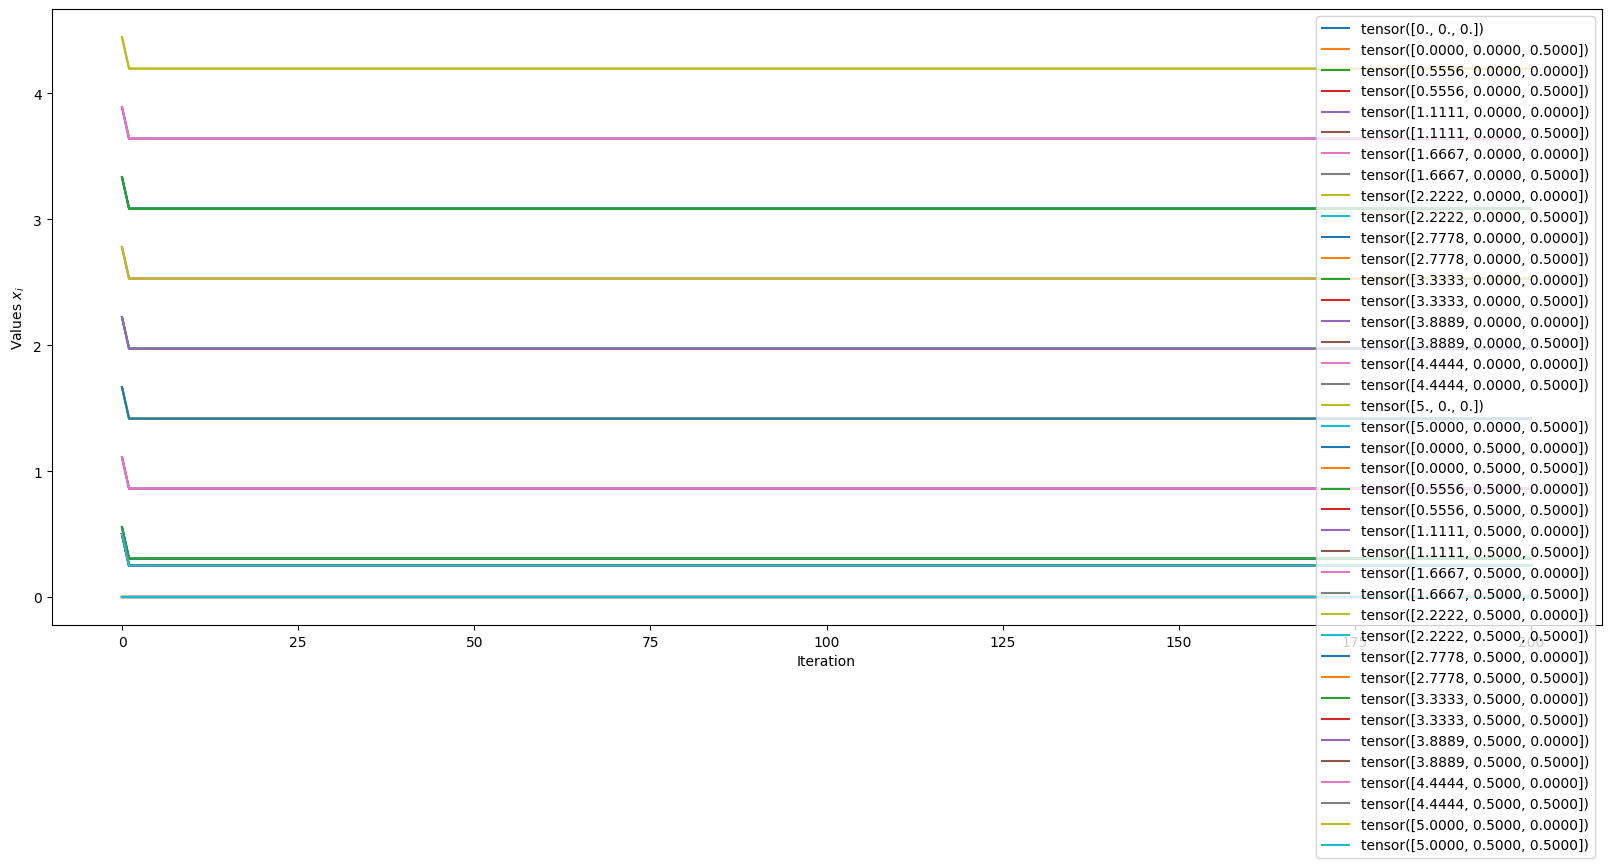

Widget(value='<iframe src="http://localhost:56674/index.html?ui=P_0x2c1cbed10_30&reconnect=auto" class="pyvist…

In [55]:
# Plot the development of design variables
plt.figure(figsize=(20, 8))
plt.plot(torch.stack(x).detach())
plt.legend(nodes)
plt.xlabel("Iteration")
plt.ylabel("Values $x_i$")
plt.show()

bridge.plot(force_size_factor = 0.1, constraint_size_factor = 0.01)


In [56]:
u, f = bridge.solve()
sigma = bridge.compute_stress(u)
bridge.plot(u=u, sigma=sigma,force_size_factor = 0.1, constraint_size_factor = 0.01)

print(u)

Widget(value='<iframe src="http://localhost:56674/index.html?ui=P_0x2c1c1d240_31&reconnect=auto" class="pyvist…

tensor([[0., 0., 0.],
        [0., 0., 0.],
        [0., 0., 0.],
        [0., 0., 0.],
        [0., 0., 0.],
        [0., 0., 0.],
        [0., 0., 0.],
        [0., 0., 0.],
        [0., 0., 0.],
        [0., 0., 0.],
        [0., 0., 0.],
        [0., 0., 0.],
        [0., 0., 0.],
        [0., 0., 0.],
        [0., 0., 0.],
        [0., 0., 0.],
        [0., 0., 0.],
        [0., 0., 0.],
        [0., 0., 0.],
        [0., 0., 0.],
        [0., 0., 0.],
        [0., 0., 0.],
        [0., 0., 0.],
        [0., 0., 0.],
        [0., 0., 0.],
        [0., 0., 0.],
        [0., 0., 0.],
        [0., 0., 0.],
        [0., 0., 0.],
        [0., 0., 0.],
        [0., 0., 0.],
        [0., 0., 0.],
        [0., 0., 0.],
        [0., 0., 0.],
        [0., 0., 0.],
        [0., 0., 0.],
        [0., 0., 0.],
        [0., 0., 0.],
        [0., 0., 0.],
        [0., 0., 0.]], grad_fn=<ViewBackward0>)
